# 01 - Exploratory data analysis

Next-day unhealthy air warning (AQI > 200) for Indian cities. This notebook uses the same code as the scripts in `src/` (`data.py`, `splits.py`) and only **looks** at the data: it fits nothing and uses no test-year labels to make any choice.

**Run from the project root** after placing `city_day.csv` in `data/raw/` (see README). One row = one city on one day *t*; target = AQI on day *t+1* is above 200.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, matplotlib.pyplot as plt
from data import load_raw, build_dataset
from splits import get_split, seen_cities
raw = load_raw()
print(raw.shape, raw.City.nunique(), "cities", raw.Date.min().date(), "to", raw.Date.max().date())
print("duplicate city-days:", raw.duplicated(["City", "Date"]).sum())

(29531, 16) 26 cities 2015-01-01 to 2020-07-01
duplicate city-days: 0


## 1. Missing values
Blank readings are the main quality issue. Xylene is dropped later (61% blank, never measured in 14 cities).

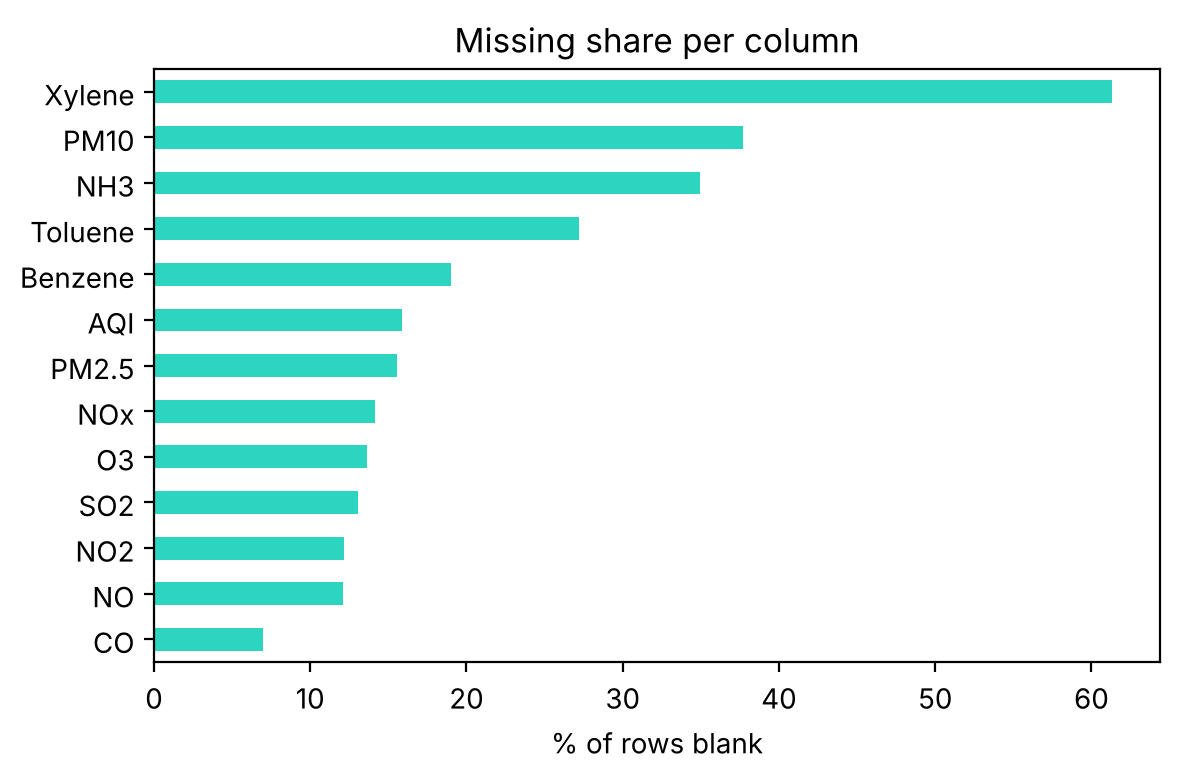

AQI max: 2049.0 | PM10 max: 1000.0 | PM2.5 max: 950 | Benzene max: 455


In [2]:
miss = (raw.drop(columns=["City", "Date", "AQI_Bucket"]).isna().mean() * 100).sort_values()
miss.plot.barh(figsize=(6, 4), color="#2dd4bf"); plt.xlabel("% of rows blank"); plt.title("Missing share per column"); plt.tight_layout(); plt.show()
print("AQI max:", raw.AQI.max(), "| PM10 max:", raw.PM10.max(), "| PM2.5 max:", round(raw['PM2.5'].max()), "| Benzene max:", round(raw.Benzene.max()))

## 2. Uneven coverage
Only some cities exist in the early years; 8 cities first appear in 2019-2020, so they are never in training.

In [3]:
cov = raw.assign(year=raw.Date.dt.year).pivot_table(index="City", columns="year", values="AQI", aggfunc="count").fillna(0).astype(int)
display(cov)
print("Mumbai days:", (raw.City == "Mumbai").sum(), "| with AQI:", raw[raw.City == "Mumbai"].AQI.notna().sum())

year,2015,2016,2017,2018,2019,2020
City,,,,,,
Ahmedabad,263,117,69,357,352,176
Aizawl,0,0,0,0,0,111
Amaravati,0,0,37,312,309,183
Amritsar,0,0,266,324,362,174
Bengaluru,286,351,364,361,365,183
Bhopal,0,0,0,0,105,173
Brajrajnagar,0,0,10,260,322,121
Chandigarh,0,0,0,0,117,182
Chennai,276,334,361,365,365,183


Mumbai days: 2009 | with AQI: 775


## 3. Target and usable rows
A row is used only if both today's and tomorrow's AQI are observed. Tomorrow is found by date, not by next row.

In [4]:
data = build_dataset(); ev = data[data.is_eval]
print("usable rows:", len(ev), "| positives:", int(ev.poor_tomorrow.sum()), f"({ev.poor_tomorrow.mean():.1%})")
by_year = ev.groupby(ev.Date.dt.year).poor_tomorrow.agg(rows="count", positive_rate="mean")
display(by_year.round(3))

usable rows: 24343 | positives: 6330 (26.0%)


,rows,positive_rate
Date,,
2015,1802,0.416
2016,2486,0.374
2017,3152,0.330
2018,5601,0.284
2019,6968,0.226
2020,4334,0.102


## 4. Seasonality and drift
Bad days cluster in winter and post-monsoon, and the bad-day rate fell from 33% (train) to 22.6% (2019). This is why recall drifts below the 80% validation target.

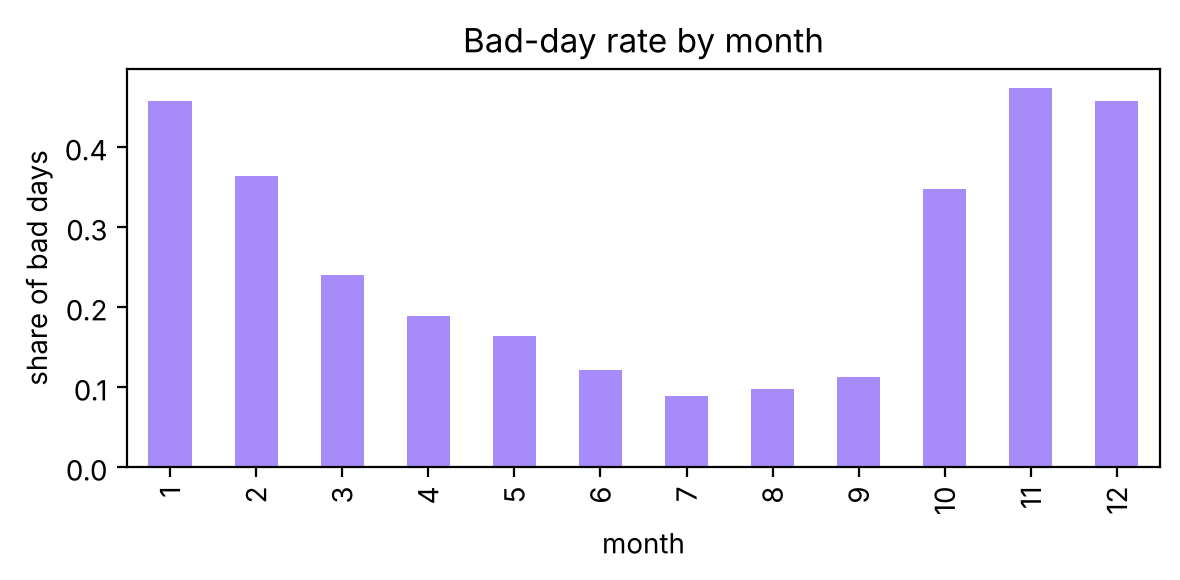

In [5]:
m = ev.groupby(ev.Date.dt.month).poor_tomorrow.mean()
m.plot.bar(figsize=(6, 3), color="#a78bfa"); plt.xlabel("month"); plt.ylabel("share of bad days"); plt.title("Bad-day rate by month"); plt.tight_layout(); plt.show()

## 5. How strong is 'tomorrow = today'?
Persistence is right on most rows, so the only place a model can add value is on **change days**, where the yes/no status flips.

In [6]:
same = (ev.AQI > 200).astype(int) == ev.poor_tomorrow.astype(int)
print(f"persistence right on {same.mean():.1%} of rows; change days: {(~same).sum()}")

persistence right on 92.8% of rows; change days: 1748


## 6. Fixed split (set before modelling)

In [7]:
seen = seen_cities(data)
rows = []
for name in ["train", "test", "pre_lockdown", "lockdown"]:
    s = get_split(data, name); rows.append({"part": name, "rows": len(s), "positives": int(s.poor_tomorrow.sum()), "new-city rows": int((~s.City.isin(seen)).sum())})
display(pd.DataFrame(rows))
print("seen cities:", len(seen), "| new cities:", raw.City.nunique() - len(seen))

,part,rows,positives,new-city rows
0,train,13024,4300,0
1,test,6946,1567,762
2,pre_lockdown,1941,409,518
3,lockdown,2369,32,702


seen cities: 18 | new cities: 8
